---
title: "Simpson's rule"
subtitle: "Lecture 11: Chapter 4: Numerical integration"
code-fold: true
format:
  html: default
  pdf: default
---

{{< include ../extras/_lecture-header.html >}}

In [3]:
# | include: false

using Plots, LaTeXStrings, Polynomials

## Previously.....

- Quadrature rules $\int_a^b f \approx \sum_j w_j f(x_j)$ (@def-quadrature-rule): integrating the interpolating polynomial gives the weights $w_j = \int_a^b \ell_j$ (@eq-interpolatory-quadrature), and equispaced nodes give the Newton–Cotes rules (@def-newton-cotes),
- Error estimates: integrate the interpolation error (@thm-Lagrange-interpolation),
- Rectangular rule $(b-a) f(a)$: exact for polynomials of degree $0$; the composite rule has error at most $\frac{\|f'\|_{L^\infty([a,b])}}{2} \frac{(b-a)^2}{n}$ (@thm-rectangular-composite),
- Trapezoid rule $\frac{b-a}{2} \big( f(a) + f(b) \big)$: exact for polynomials of degree $1$; the composite rule has error at most $\frac{\|f''\|_{L^\infty([a,b])}}{12} \frac{(b-a)^3}{n^2}$ (@thm-trapezoid-composite).

::: {.box}

**Exercise.** @exr-l10-weights

:::

We continue with the function from @exm-l10-model-problem:

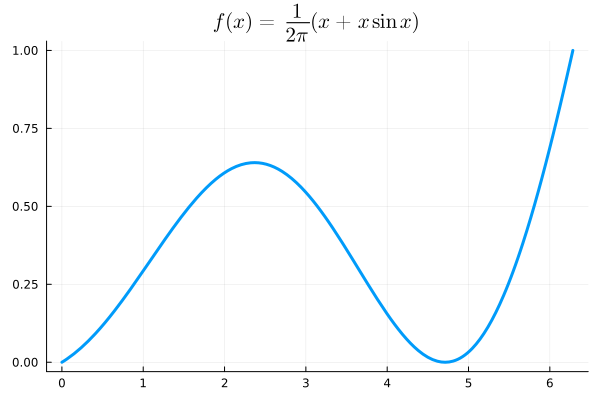

In [2]:
a, b = 0, 2π
f = x -> x * ( 1 + sin(x) ) /( 2π )
df_max = 1 + 1/(2π)

# maximum of |f''|, |f'''|, |f''''| on [a,b] (computed on a fine grid)
d2f = x -> ( 2cos(x) - x * sin(x) ) /( 2π )
d3f = x -> ( -3sin(x) - x * cos(x) ) /( 2π )
d4f = x -> ( -4cos(x) + x * sin(x) ) /( 2π )
X = range(a, b, 10^5)
d2f_max = maximum( abs.( d2f.(X) ) )
d3f_max = maximum( abs.( d3f.(X) ) )
d4f_max = maximum( abs.( d4f.(X) ) )
plot( f, a, b, title=L"f(x) = \frac{1}{2\pi} (x + x\sin x ) ", lw = 3, legend=false)

## Simpson's rule

Rectangular, and trapezoid rules were exact for polynomials of degree $0$ and $1$, respectively. Simpson's rule is exact for degree $2$ polynomials: 

::: {#exr-l11-guess-simpson}

[](../exercises/bank.html#bank-exr-l11-guess-simpson)

Suppose you know $f(0)$, $f(\tfrac12)$ and $f(1)$. Find weights $\hat w_0, \hat w_1, \hat w_2$ so that 

\begin{align}
    \int_0^1 f(x) \mathrm{d}x 
    %
    &\approx \hat w_0 f(0) + \hat w_1 f(\tfrac{1}2) + \hat w_2 f(1)
\end{align} 

is exact for $f = 1$, $x$ and $x^2$.

::: {.exercise-hint style="display: none;"}

Notice that 

\begin{align}
    \int_0^1 f(x)\mathrm{d}x = \begin{cases} 
        1 &\text{if } f = 1, \nonumber\\
        1/2 &\text{if } f = x, \nonumber\\
        1/3 &\text{if } f = x^2 
    \end{cases}
\end{align}

and solve the resulting linear system of equations.

:::

::: {.exercise-solution style="display: none;"}

Exactness for $1, x, x^2$ gives

$$
\begin{align}
    1 &= \hat w_0 + \hat w_1 + \hat w_2 , \nonumber\\
    \tfrac12 &= 0 \cdot \hat w_0 + \tfrac12 \hat w_1 + 1 \cdot \hat w_2, \nonumber\\
    \tfrac13 &= 0^2 \hat w_0 + (\tfrac12)^2 \hat w_1 + 1^2 \hat w_2 \nonumber
\end{align}
$$

Subtracting the last two equations gives $\frac14 \hat w_1 = \frac16$, so $\hat w_1 = \frac23$, then $\hat w_2 = \frac16$ and $\hat w_0 = \frac16$. 

This is Simpson's rule (it was already known to Kepler in 1615 as his *barrel rule* for the volume of wine barrels).

:::

:::

More generally, for $X = \{a, \frac{a+b}{2}, b\}$, we let $p_2$ be the quadratic interpolation of $f$ on $X$ and approximate 

$$
\begin{align}
    \int_a^b f(x) \mathrm{d}x &\approx 
    \int_a^b p_2(x) \mathrm{d}x \nonumber\\
    %
    &= \frac{b-a}{6} \left[ f(a) + 4 f\big(\tfrac{a+b}{2}\big) + f(b) \right].
\end{align}
$$ {#eq-simpson-rule}

Here, you can write out the polynomial interpolation using the Lagrange polynomials and evaluate the weights $w_j = \int_a^b \ell_j$ explicitly, or do the same in the Newton basis. Instead, notice that $a, \frac{a+b}{2}, b$ are the images of the nodes $0, \frac12, 1$ under $t \mapsto a + (b-a) t$. By @exr-l11-guess-simpson, the weights $\hat w_0 = \hat w_2 = \frac16$ and $\hat w_1 = \frac23$ give a rule on $[0,1]$ that is exact for all polynomials of degree at most $2$, and so, by @exr-l10-weights (1), they are the weights $\hat w_j = \int_0^1 \hat \ell_j$ of the interpolatory rule on $\{0, \frac12, 1\}$. Therefore, by @exr-l10-weights (3), the weights on $[a,b]$ are $w_j = (b-a) \hat w_j$, which gives @eq-simpson-rule.

::: {#thm-simpson-error-1 name="Error estimate"}

Suppose $f \in C^3([a,b])$. Then

$$
\begin{align}
    \left| \int_{a}^b f - \frac{b-a}{6} \left[ f(a) + 4 f\big(\tfrac{a+b}{2}\big) + f(b) \right] \right| \leq \frac{\| f'''\|_{L^\infty([a,b])}}{192} (b-a)^4.
\end{align}
$$

:::

::: {.proof}
Since $p_2$ is a degree two interpolating polynomial, we may apply the error bound we had for interpolation (@thm-Lagrange-interpolation): 

$$
\begin{align}
    f(x) - p_2(x) = \frac{f'''(\xi_x)}{3!} (x - a)\big( x - \tfrac{a+b}{2} \big) (x-b) 
\end{align}
$$

for some $\xi_x \in [a, b]$. Therefore, integrating this over $[a,b]$, we have the bound

$$
\begin{align}
    &\left| \int_{a}^b \big[ f(x) - p_2(x) \big] \mathrm{d}x \right| 
    %
    \nonumber\\
    &\leq \frac{\| f'''\|_{L^\infty([a,b])}}{6} \int_a^b \left|(x - a)\big( x - \tfrac{a+b}{2} \big) (x-b)\right| \mathrm{d}x \nonumber\\
    &= \frac{\| f'''\|_{L^\infty([a,b])}}{6} \frac{(b-a)^4}{32}. \nonumber
\end{align}
$$

For the last integral, make the substitution $t := x - \frac{a+b}{2}$ and define $h := b - a$, so that $(x-a)(x-b) = t^2 - \frac{h^2}{4} \leq 0$ for $t \in [-\frac{h}{2}, \frac{h}{2}]$. Then, since the integrand is even,

$$
\begin{align}
    &\int_a^b \left|(x - a)\big( x - \tfrac{a+b}{2} \big) (x-b)\right| \mathrm{d}x
    %
    \nonumber\\
    &= \int_{-h/2}^{h/2} |t| \big( \tfrac{h^2}{4} - t^2 \big) \mathrm{d}t \nonumber\\
    %
    &= 2 \int_{0}^{h/2} \big( \tfrac{h^2}{4} t - t^3 \big) \mathrm{d}t \nonumber\\
    %
    &= 2 \Big( \frac{h^4}{32} - \frac{h^4}{64} \Big)
    = \frac{(b-a)^4}{32}, \nonumber
\end{align}
$$

as required.

:::

***Composite rule.*** This error bound is only useful if $[a,b]$ is a small interval (or $f'''$ is small). It therefore makes sense to split the interval $[a,b]$ into subintervals and consider the Simpson rule on each one. We will now consider $n$ even and $x_j = a + j\frac{b-a}{n}$ for $j = 0,\dots,n$ and write

$$
\begin{align}
    \int_a^b f &= \sum_{j=0 : \text{ even}}^{n-2} \int_{x_j}^{x_{j+2}} f \nonumber\\
    %
    &\approx \sum_{j=0 : \text{ even}}^{n-2} \frac{x_{j+2} - x_j}{6} \big[ f(x_j) + 4 f(x_{j+1}) + f(x_{j+2}) \big] \nonumber\\
    %
    &= \frac{b-a}{3n} \left[  f(x_0) + 4 f(x_{1}) + 2 f(x_{2}) + 4 f(x_3) + 2 f(x_{4}) + \dots + 4 f(x_{n-1}) + f(x_n) \right]
\end{align}
$$

(we have changed notation here slightly so that we are interpolating $f$ only at points in $X = \{x_0, \dots, x_n\}$). This is a quadrature rule with weights $w_0 = w_n = \frac{x_{n} - x_{n-2}}{6} = \frac{b-a}{3 n}$, and $w_{2j+1} = \frac{b-a}{3n} \cdot 4$ and $w_{2j} = \frac{b-a}{3n} \cdot 2$ otherwise. 

::: {#thm-simpson-composite-1}

Suppose $f \in C^3([a,b])$ and $n$ is even. Then the composite Simpson rule satisfies

$$
\begin{align}
    \left| \int_a^b f - \sum_{j = 0}^n w_j f(x_j) \right| \leq  \frac{\| f'''\|_{L^\infty([a,b])}}{24} \frac{(b-a)^4}{n^3}.
\end{align}
$$

:::

::: {.proof}
Using @thm-simpson-error-1 on each of the $\frac n2$ subintervals $[x_j, x_{j+2}]$ (which have length $2 \frac{b-a}{n}$) and summing over $j$, we obtain

$$
\begin{align}
    \left| \int_a^b f - \sum_{j = 0}^n w_j f(x_j) \right| &\leq  \| f'''\|_{L^\infty([a,b])} \sum_{j=0 : \text{ even}}^{n-2} \frac1{192} \left(2 \cdot \frac{b-a}{n}\right)^4 \nonumber\\
    %
    &=  \frac{\| f'''\|_{L^\infty([a,b])}}{24} \frac{(b-a)^4}{n^3}. \nonumber
\end{align}
$$
:::

::: {#rem-simpson-exact}
Notice that this quadrature rule is exact if $f$ is a polynomial of degree $2$.
:::

***Numerics.*** We now test this numerically:

Plots.AnimatedGif("C:\\Users\\jack6\\Projects\\Math5485-Fall-2026\\images\\Simpson.gif")
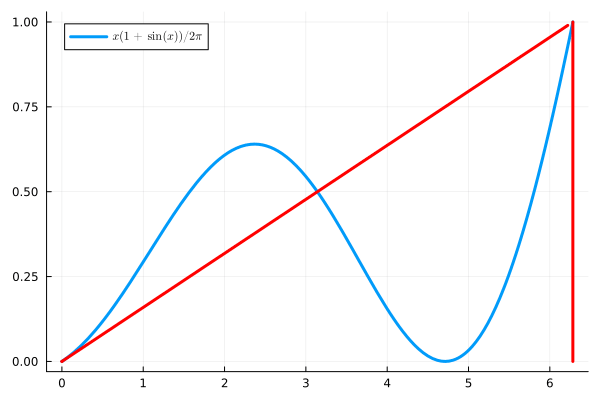

In [3]:
N = 15
S = []

anim = @animate for n ∈ 1:N
    
    h = (b-a)/(2*n)
    x = [a + j*(b-a)/(2*n) for j in 0:(2*n)]
    
    p = 0
    for j in 0:2*n
        if j==0
            p = p + f( x[j+1] )
        elseif j==2*n 
            p = p + f( x[j+1] )
        elseif mod(j,2)==0
            p = p + 2*f( x[j+1] )
        else
            p = p + 4*f( x[j+1] )
        end
    end
    push!( S, h*p/3 )
    
    plot( f, a, b, label=L"x( 1 + \sin(x) )/2π", lw = 3)

    for m ∈ 1:2:2n

        p = fit( [x[m], x[m+1], x[m+2]], [f(x[m]), f(x[m+1]), f(x[m+2])] )

        plot!( p, x[m], x[m+2], lw=3, color="red", primary=false)
        plot!([x[m], x[m]], [0, f(x[m])], lw=3, color="red", primary=false)
        plot!([x[m+2], x[m+2]], [0, f(x[m+2])], lw=3, color="red", primary=false)
    end

end

gif(anim, "../images/Simpson.gif", fps = 1, show_msg = false)

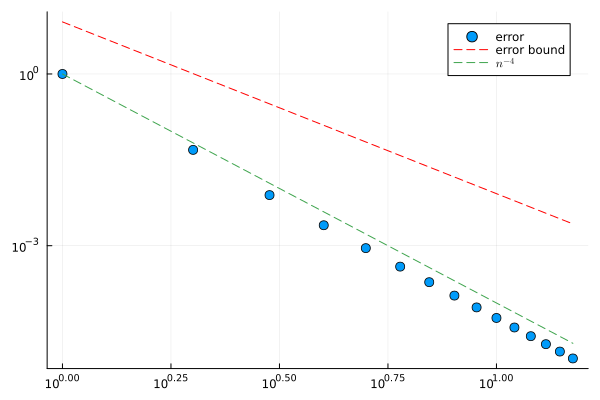

In [4]:
scatter( abs.(S .- (π -1)), xaxis=:log, yaxis=:log, markersize=5, label="error")
plot!( (1/24)*d3f_max*(b-a)^4*(2*(1:N)).^(-3), linestyle=:dash, color=:red, label="error bound" )   # S[n] uses 2n subintervals
plot!( (1:N).^(-4), linestyle=:dash, label=L"n^{-4}" )

Therefore the error bound we have derived is an upper bound in this case! However, it seems that the error is $O(n^{-4})$ not $O(n^{-3})$ (which is what our error bound says). We will see now that we actually get an improved error bound.

## Improved error estimate for Simpson's rule

Recall that we are considering the (composite) Simpson rule: 

$$
\begin{align}
    \int_a^b f &\approx \sum_{j=0 : \text{ even}}^{n-2} \frac{b-a}{3n} \big[ f(x_j) + 4 f(x_{j+1}) + f(x_{j+2}) \big]
\end{align}
$$

(with $n$ even). We have seen that the quadrature rule is exact when $f$ is a quadratic polynomial (degree 2). We will now see that it is also exact when $f$ is a cubic polynomial (degree 3).

::: {#exr-l11-cubic-preview}

[](../exercises/bank.html#bank-exr-l11-cubic-preview)

1. What is the quadratic interpolant of $f(x) = x^2$ on $\{-1, 0, 1\}$?
2. What is the cubic interpolant $p$ of $f(x) = x^3$ on $\{-1, 0, 1\}$? Compare $\int_{-1}^1 f$ and $\int_{-1}^1 p$.
3. Why is $\int_a^b \big(x - \tfrac{a+b}{2}\big)^3 \,\mathrm{d}x = 0$?

::: {.exercise-solution style="display: none;"}

1. $p(x) = x^2$: since $f \in \mathcal P_2$, the interpolant is $f$ itself.
2. $f(-1) = -1$, $f(0) = 0$, $f(1) = 1$, so $p(x) = x$. Both integrals vanish: $\int_{-1}^1 x^3 = 0 = \int_{-1}^1 x$. So integrating the quadratic interpolant gives the exact integral of this cubic.
3. With $t = x - \frac{a+b}{2}$ the integral is $\int_{-h}^{h} t^3 \,\mathrm{d}t$ with $h = \frac{b-a}{2}$, and $t \mapsto t^3$ is odd.

:::

:::

::: {#thm-simpson-cubic}

Simpson's rule @eq-simpson-rule (and therefore also the composite Simpson rule) is exact for all polynomials of degree at most $3$.

:::

::: {.proof}
We may write $f(x) = \alpha \big( x - \tfrac{a+b}{2} \big)^3  +  g(x)$ where $g$ is a quadratic polynomial. Since $t \mapsto t^3$ is an odd function, we have 

$$
\begin{align}
   0 &= \int_{a}^{b} \big( x - \tfrac{a+b}{2} \big)^3 \mathrm{d}x \nonumber\\
    %
    &= \frac{b-a}{6} \Big[ \big( a - \tfrac{a+b}{2} \big)^3 + 4 \big(  \tfrac{a+b}{2}  - \tfrac{a+b}{2} \big)^3 +  \big( b - \tfrac{a+b}{2} \big)^3 \Big]
\end{align}
$$

and thus 

$$
\begin{align}
    \int_{a}^b f &= \int_{a}^b \Big[ \alpha \big( x - \tfrac{a+b}{2} \big)^3  +  g(x) \Big] \mathrm{d}x \nonumber\\
    %
    &= 0 + \frac{b-a}{6} \big[ g(a) + 4 g\big(\tfrac{a+b}{2}\big) + g(b) \big] \nonumber\\
    %
    &= \frac{b-a}{6} \big[ f(a) + 4 f\big(\tfrac{a+b}{2}\big) + f(b) \big].
\end{align}
$$

As a result, Simpson's quadrature rule is exact for all cubic functions. The composite rule is the sum of Simpson's rule on each subinterval and so this is also exact on polynomials of degree $3$.
:::

We now turn our attention to error estimates. 

::: {#thm-simpson-error}

Suppose $f \in C^4([a,b])$. Then

$$
\begin{align}
    \left| \int_a^b f - \frac{b-a}{6} \big[ f(a) + 4 f\big(\tfrac{a+b}{2}\big) + f(b) \big] \right| \leq \frac{\| f'''' \|_{L^\infty([a,b])}}{2880} (b-a)^5
\end{align}
$$

and, for $n$ even, the composite Simpson rule satisfies

$$
\begin{align}
    \left| \int_a^b f - \frac{b-a}{3n} \sum_{j=0 : \text{ even}}^{n-2} \big[ f(x_j) + 4 f(x_{j+1}) + f(x_{j+2}) \big] \right| \leq \frac{\| f'''' \|_{L^\infty([a,b])}}{180} \frac{(b-a)^5}{n^4}.
\end{align}
$$

:::

::: {.proof}
Let $p$ be the (degree less than or equal to $3$) Hermite polynomial interpolation of $f$ on $\{\{ a, b, \tfrac{a+b}2, \tfrac{a+b}2 \}\}$. Since $p = f$ at $a, \tfrac{a+b}{2}, b$ and Simpson's rule is exact for $p$ (@thm-simpson-cubic), using the error estimate for Hermite interpolation (@exr-l09-hermite-error), there exists $\xi_x \in [a,b]$ such that

$$
\begin{align}
    &\left| \int_a^b f - \frac{b-a}{6} \big[ f(a) + 4 f\big(\tfrac{a+b}{2}\big) + f(b) \big] \right|
    %
    \nonumber\\
    &= \left| \int_a^b f - \frac{b-a}{6} \big[ p(a) + 4 p\big(\tfrac{a+b}{2}\big) + p(b) \big] \right| \nonumber\\
    %
    &= \left| \int_a^b \big( f - p \big) \right| \nonumber\\
    %
    &= \left| \int_a^b \frac{f''''(\xi_x)}{4!} (x-a)\big( x - \tfrac{a+b}2 \big)^2 (x-b) \mathrm{d}x \right| \nonumber\\
    %
    &\leq \frac{\| f'''' \|_{L^\infty([a,b])}}{4!} \left| \int_a^b (x-a)\big( x - \tfrac{a+b}2 \big)^2 (x-b) \mathrm{d}x \right| \nonumber\\
    %
    &= \frac{\| f'''' \|_{L^\infty([a,b])}}{4!} \frac{(b-a)^5}{120}. \nonumber
\end{align}
$$

Here, we have used the fact that $x \mapsto (x-a)\big( x - \tfrac{a+b}2 \big)^2 (x-b)$ doesn't change sign on $[a,b]$. For the last integral, as before, we make the substitution $t := x - \frac{a+b}{2}$ and define $h := b - a$, so that

$$
\begin{align}
    &\int_a^b (x-a)\big( x - \tfrac{a+b}2 \big)^2 (x-b) \mathrm{d}x
    %
    \nonumber\\
    &= \int_{-h/2}^{h/2} t^2 \big( t^2 - \tfrac{h^2}{4} \big) \mathrm{d}t \nonumber\\
    %
    &= 2 \Big[ \frac{t^5}{5} - \frac{h^2 t^3}{12} \Big]_0^{h/2} \nonumber\\
    %
    &= 2 \Big( \frac{h^5}{160} - \frac{h^5}{96} \Big)
    = -\frac{(b-a)^5}{120}. \nonumber
\end{align}
$$

Then, the error for the composite rule is bounded above as follows:

$$
\begin{align}
    &\left| \int_a^b f - \frac{b-a}{3n} \sum_{j=0 : \text{ even}}^{n-2} \big[ f(x_j) + 4 f(x_{j+1}) + f(x_{j+2}) \big] \right| \nonumber\\
    %
    &\leq \sum_{j=0 : \text{ even}}^{n-2} \left| \int_{x_j}^{x_{j+2}} f - \frac{x_{j+2}-x_{j}}{6} \big[ f(x_j) + 4 f\big(x_{j+1}\big) + f(x_{j+2}) \big] \right| \nonumber\\
    %
    &\leq \frac{\| f'''' \|_{L^\infty([a,b])}}{4!} \frac{n}{2} \frac{1}{120} \left(2\frac{b-a}{n}\right)^5
    %
    = \frac{\| f'''' \|_{L^\infty([a,b])}}{180} \frac{(b-a)^5}{n^4}, \nonumber
\end{align}
$$

as required.

:::

This gives us the correct rate:

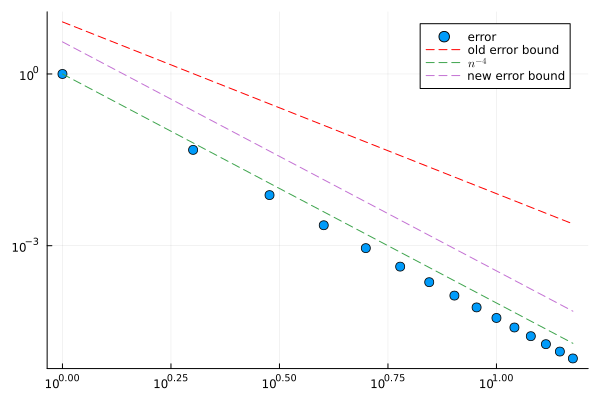

In [5]:
scatter( abs.(S .- (π -1)), xaxis=:log, yaxis=:log, markersize=5, label="error")
plot!( (1/24)*d3f_max*(b-a)^4*(2*(1:N)).^(-3), linestyle=:dash, color=:red, label="old error bound" )
plot!( (1:N).^(-4), linestyle=:dash, label=L"n^{-4}" )
plot!( (1/180)*d4f_max*(b-a)^5*(2*(1:N)).^(-4), linestyle=:dash, label="new error bound" )

## Summary

1. Simpson's rule is given by $\frac{b-a}{6} \left( f(a) + 4 f(\tfrac{a+b}2) + f(b) \right)$ and is exact for all polynomials of degree at most $3$ (@thm-simpson-cubic),
2. Integrating the interpolation error gives a composite rule with error $C \|f'''\|_{L^\infty([a,b])} n^{-3}$ (@thm-simpson-composite-1), which is not sharp,
3. Using Hermite interpolation, the composite rule has error $C \|f''''\|_{L^\infty([a,b])} n^{-4}$ (@thm-simpson-error),
4. Rectangular, trapezoid and Simpson rules: $O(n^{-1})$, $O(n^{-2})$ and $O(n^{-4})$.

## Next time....

- Gaussian quadrature: choosing the nodes **and** the weights so that the rule is exact for polynomials of degree $2n+1$,
- Orthogonal polynomials.

::: {.callout-tip}
# TO-DO

* Exercises throughout the notes,
* (Sign-up to office hours if you like)

:::

## Extra exercises

::: {#exr-l11-sharp name="The error bounds are sharp"}

[](../exercises/bank.html#bank-exr-l11-sharp)

1. Compute the error of the trapezoid rule for $f(x) = x^2$ on $[0,1]$ and compare it with the bound in @thm-trapezoid-error.
2. Compute the error of Simpson's rule for $f(x) = x^4$ on $[0,1]$ and compare it with the bound in @thm-simpson-error.
3. Explain why this shows that Simpson's rule is not exact for all polynomials of degree $4$.

::: {.exercise-solution style="display: none;"}

1. $\int_0^1 x^2 \,\mathrm{d}x = \frac13$ and the trapezoid rule gives $\frac12 (0 + 1) = \frac12$, so the error is $\frac12 - \frac13 = \frac16$. The bound is $\frac{\|f''\|_{L^\infty}}{12} (1 - 0)^3 = \frac{2}{12} = \frac16$, so the bound is attained.

2. $\int_0^1 x^4 \,\mathrm{d}x = \frac15$ and Simpson's rule gives $\frac16 \big( 0 + 4 \cdot \frac1{16} + 1 \big) = \frac16 \cdot \frac54 = \frac{5}{24}$, so the error is $\frac{5}{24} - \frac15 = \frac{1}{120}$. The bound is $\frac{\|f''''\|_{L^\infty}}{2880} = \frac{24}{2880} = \frac{1}{120}$, so again the bound is attained.

3. The error in 2 is non-zero, so Simpson's rule is not exact for $x^4 \in \mathcal P_4$. Together with @thm-simpson-cubic, Simpson's rule is exact on $\mathcal P_3$ but not on $\mathcal P_4$.

:::

:::

::: {#exr-l11-simpson-38 name="Simpson's 3/8 rule"}

[](../exercises/bank.html#bank-exr-l11-simpson-38)

Let $h = \frac{b-a}{3}$ and consider the Newton–Cotes rule with the four nodes $a, a + h, a + 2h, b$.

1. Show that the rule is
$$
    \int_a^b f \approx \frac{b-a}{8} \big[ f(a) + 3 f(a+h) + 3 f(a+2h) + f(b) \big].
$$
2. Show that this rule is exact for all polynomials of degree at most $3$, but not for $x^4$.
3. Compute the error of this rule for $f(x) = x^4$ on $[0,1]$ and compare it with the error of Simpson's rule from @exr-l11-sharp.

::: {.exercise-hint style="display: none;"}

Use @exr-l10-weights: it is enough to find the weights on $[0,1]$, and the weights are symmetric, so there are only two unknowns $\hat w_0 = \hat w_3$ and $\hat w_1 = \hat w_2$.

:::

::: {.exercise-solution style="display: none;"}

1. By @exr-l10-weights (3), it is enough to work on $[0,1]$ with nodes $0, \frac13, \frac23, 1$. By @exr-l10-weights (4), $\hat w_0 = \hat w_3 =: \alpha$ and $\hat w_1 = \hat w_2 =: \beta$. Exactness on $1$ and $x^2$ gives
$$
\begin{align}
    1 &= 2\alpha + 2\beta, \nonumber\\
    \frac13 &= \alpha \Big(0 + 1\Big) + \beta \Big( \frac19 + \frac49 \Big) \nonumber\\
    &= \alpha + \frac59 \beta.
\end{align}
$$
From the first, $\alpha = \frac12 - \beta$, so $\frac13 = \frac12 - \frac49 \beta$, i.e. $\beta = \frac38$ and $\alpha = \frac18$. Scaling by $b-a$ gives the stated rule.

2. The rule is interpolatory with $4$ nodes, so it is exact on $\mathcal P_3$ by @exr-l10-weights (1). For $x^4$, see 3.

3. On $[0,1]$ the rule gives $\frac18 \big[ 0 + 3 \cdot \frac1{81} + 3 \cdot \frac{16}{81} + 1 \big] = \frac18 \cdot \frac{132}{81} = \frac{11}{54}$, whereas $\int_0^1 x^4 = \frac15$. The error is $\frac{11}{54} - \frac15 = \frac{1}{270} \not= 0$, so the rule is not exact on $\mathcal P_4$.

Simpson's rule has error $\frac1{120}$ using $3$ function evaluations, while the 3/8 rule has the smaller error $\frac1{270}$ but uses $4$. Both rules are exact on $\mathcal P_3$ (but not $\mathcal P_4$), so their composite versions both converge at rate $O(n^{-4})$.

:::

:::

::: {#exr-l11-radau name="Choosing the nodes as well"}

[](../exercises/bank.html#bank-exr-l11-radau)

Consider rules on $[0,1]$ of the form $\int_0^1 f \approx w_0 f(0) + w_1 f(x_1)$ where $w_0, w_1$ **and** $x_1 \in (0,1]$ are free.

1. Find $w_0, w_1, x_1$ so that the rule is exact for all polynomials of degree at most $2$.
2. Show that the resulting rule is not exact for $x^3$.
3. Compare with the trapezoid rule (which also uses two nodes, one of which is $0$). What is the largest degree $d$ for which you could hope to find a rule $w_0 f(y_0) + w_1 f(y_1)$ (with both nodes free) that is exact on $\mathcal P_d$?

::: {.exercise-hint style="display: none;"}

1. Write down the three equations obtained from exactness on $1, x, x^2$. 
3. Count the unknowns.

:::

::: {.exercise-solution style="display: none;"}

1. Exactness on $1, x, x^2$ gives
$$
\begin{align}
    w_0 + w_1 &= 1, \nonumber\\ w_1 x_1 &= \frac12, \nonumber\\ w_1 x_1^2 &= \frac13.
\end{align}
$$
Dividing the third by the second gives $x_1 = \frac23$, then $w_1 = \frac34$ and $w_0 = \frac14$. The rule is $\int_0^1 f \approx \frac14 f(0) + \frac34 f\big(\frac23\big)$.

2. $\frac34 \big(\frac23\big)^3 = \frac{2}{9} \not= \frac14 = \int_0^1 x^3$.

3. The trapezoid rule $\frac12 \big( f(0) + f(1) \big)$ is exact on $\mathcal P_1$ only: by freeing the second node we gained one degree of exactness. With both nodes free there are $4$ unknowns $w_0, w_1, y_0, y_1$ and exactness on $\mathcal P_d$ imposes $d+1$ equations, so we may hope for $d = 3$. This is *Gaussian quadrature*, which we will see next time: the nodes $y_{0,1} = \frac12 \mp \frac{1}{2\sqrt3}$ with $w_0 = w_1 = \frac12$ give a rule exact on $\mathcal P_3$.

:::

:::

::: {#exr-l11-high-order .difficult}

[](../exercises/bank.html#bank-exr-l11-high-order)

In this exercise, we see why we use composite rules rather than Newton–Cotes rules with many nodes.

1. Write a Julia function `nc_weights(n)` which returns the weights $\hat w_0, \dots, \hat w_n$ of the Newton–Cotes rule on $[0,1]$ with nodes $\hat x_j = \frac{j}{n}$. (You may solve the linear system obtained from exactness on $1, x, \dots, x^n$, or integrate the Lagrange polynomials using `Polynomials.jl`.)
2. For $n = 1, \dots, 12$, print the weights. For which $n$ do negative weights first appear? Plot $\sum_j |\hat w_j|$ against $n$.
3. Suppose that the values $f(x_j)$ are only known up to errors $|\varepsilon_j| \leq \varepsilon$. Show that the computed quadrature differs from $\sum_j w_j f(x_j)$ by at most $\varepsilon \sum_j |w_j|$. Why is it desirable to have positive weights?
4. Apply the Newton–Cotes rule with $n + 1$ nodes on $[-1,1]$ to Runge's function $f(x) = \frac{1}{1 + 25x^2}$ (@exm-Runge) for $n = 2, 4, \dots, 20$ and plot the error (the exact integral is $\frac25 \arctan 5$). Compare with the composite Simpson rule using the same nodes.

::: {.exercise-hint style="display: none;"}

1. Exactness on $x^k$ means 
$$
\begin{align}
    \sum_{j=0}^n \hat w_j \hat x_j^k &= \int_0^1 x^k \, \mathrm{d}x 
    \nonumber\\
    &= \frac{1}{k+1}
\end{align}
$$ 
for $k = 0, \dots, n$. In other words, $V^T \hat w = m$ where $m = \big(1, \frac12, \dots, \frac{1}{n+1}\big)^T$ and $V$ is the *Vandermonde matrix*
$$
    V = \begin{pmatrix} 1 & \hat x_0 & \hat x_0^2 & \cdots & \hat x_0^n \\ 1 & \hat x_1 & \hat x_1^2 & \cdots & \hat x_1^n \\ \vdots & \vdots & \vdots & & \vdots \\ 1 & \hat x_n & \hat x_n^2 & \cdots & \hat x_n^n \end{pmatrix}.
$$
($V_{jk} = \hat x_j^k$ for $0 \leq j, k \leq n$). Exact rational arithmetic (e.g. `(0:n) .// big(n)`) avoids the ill-conditioning of $V$.
4. Use @exr-l10-weights (3) to convert the weights on $[0,1]$ to weights on $[-1,1]$.

:::

::: {.exercise-solution style="display: none;"}

1. For example, using the Vandermonde system in exact rational arithmetic:


In [4]:
function nc_weights(n)
    x = (0:n) .// big(n)   # BigInt: Rational{Int64} overflows for n ≥ 11
    V = [ x[j+1]^k for k in 0:n, j in 0:n ]
    m = [ 1 // (k+1) for k in 0:n ]
    return V \ m
end

nc_weights (generic function with 1 method)

2. Negative weights first appear for $n = 8$:
$\hat w = \frac{1}{28350} (989, 5888, -928, 10496, -4540, 10496, -928, 5888, 989)$. The sum $\sum_j \hat w_j = 1$ always (@exr-l10-weights), but $\sum_j |\hat w_j| > 1$ as soon as there are negative weights ($n = 8$ and $n \geq 10$): it is about $2.3$ for $n = 12$ and grows exponentially as $n \to \infty$.

n = 1: 1//2, 1//2
n = 2: 1//6, 2//3, 1//6
n = 3: 1//8, 3//8, 3//8, 1//8
n = 4: 7//90, 16//45, 2//15, 16//45, 7//90
n = 5: 19//288, 25//96, 25//144, 25//144, 25//96, 19//288
n = 6: 41//840, 9//35, 9//280, 34//105, 9//280, 9//35, 41//840
n = 7: 751//17280, 3577//17280, 49//640, 2989//17280, 2989//17280, 49//640, 3577//17280, 751//17280
n = 8: 989//28350, 2944//14175, -464//14175, 5248//14175, -454//2835, 5248//14175, -464//14175, 2944//14175, 989//28350
n = 9: 2857//89600, 15741//89600, 27//2240, 1209//5600, 2889//44800, 2889//44800, 1209//5600, 27//2240, 15741//89600, 2857//89600
n = 10: 16067//598752, 26575//149688, -16175//199584, 5675//12474, -4825//11088, 17807//24948, -4825//11088, 5675//12474, -16175//199584, 26575//149688, 16067//598752
n = 11: 434293//17418240, 4495513//29030400, -3237113//87091200, 560593//1935360, -1599257//14515200, 2582261//14515200, 2582261//14515200, -1599257//14515200, 560593//1935360, -3237113//87091200, 4495513//29030400, 434293//17418240
n = 12: 136465

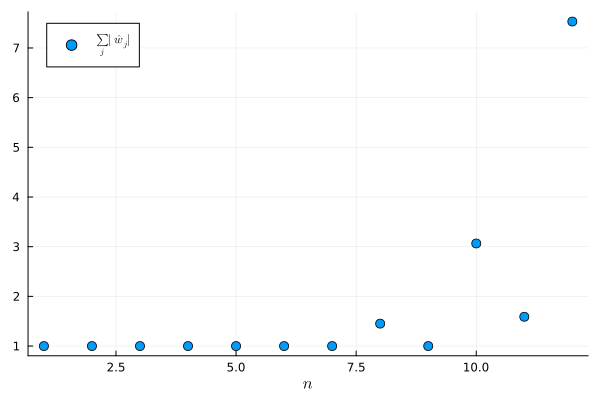

In [5]:
W = [ nc_weights(n) for n in 1:12 ]
for n in 1:12
    println("n = ", n, ": ", join(W[n], ", "))
end
println("negative weights first appear for n = ", findfirst( w -> any(w .< 0), W ))

scatter( 1:12, [ Float64(sum(abs.(w))) for w in W ], markersize=5, xlabel=L"n", label=L"\sum_j |\hat w_j|" )

3. $\big| \sum_j w_j (f(x_j) + \varepsilon_j) - \sum_j w_j f(x_j) \big| = \big| \sum_j w_j \varepsilon_j \big| \leq \varepsilon \sum_j |w_j|$. If all the weights are positive, then $\sum_j |w_j| = \sum_j w_j = b - a$ and so errors in the data are not amplified. With large negative weights, small errors in $f(x_j)$ (e.g. rounding errors) can be amplified enormously.

4. The Newton–Cotes rule integrates the equispaced interpolant, which suffers from the Runge phenomenon, so the error does not go to zero as $n$ increases: in fact, it grows (to about $6$ for $n = 20$). The composite Simpson rule with the same nodes converges at rate $O(n^{-4})$ by @thm-simpson-error.

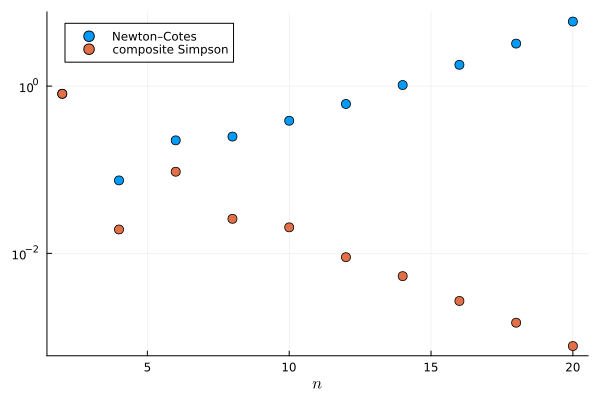

In [6]:
f = x -> 1 / ( 1 + 25x^2 )
I = (2/5) * atan(5)

function newton_cotes(f, a, b, n)
    w = (b - a) .* Float64.( nc_weights(n) )   # weights on [a,b] (@exr-l10-weights (3))
    x = range(a, b, n+1)
    return sum( w .* f.(x) )
end

function simpson(f, a, b, n)                   # composite Simpson rule on n subintervals (n even)
    x = range(a, b, n+1)
    h = (b - a) / n
    return h/3 * ( f(x[1]) + 4sum( f.(x[2:2:n]) ) + 2sum( f.(x[3:2:n-1]) ) + f(x[n+1]) )
end

N = 2:2:20
E_nc = [ abs( newton_cotes(f, -1, 1, n) - I ) for n in N ]
E_s  = [ abs( simpson(f, -1, 1, n) - I ) for n in N ]

scatter( N, E_nc, yaxis=:log, markersize=5, xlabel=L"n", label="Newton–Cotes" )
scatter!( N, E_s, markersize=5, label="composite Simpson" )

:::

:::